# Leyenda: Deliverable 1, binary classification of Photo vs non-Photo

## 1. Business context

TouNum digitises paper document collections for companies and wants to add automatic categorisation to its services. Its end goal is to caption photographs automatically, but the scanned archives also contain composed documents, diagrams, drawings and paintings. Photos must therefore be separated from the other image types before any content analysis.

### Task

Binary classification with neural networks: Photo = 1 against Painting, Schematics, Sketch and Text = 0, on images TouNum has already categorised.

### Content of this notebook

We start from two reference models (majority class, and a decision tree on image metadata), then train an MLP, a CNN from scratch with improvement methods, and a pretrained MobileNetV2. Models are selected on validation only; the test set is scored once per model, on its natural distribution, and never used to make a choice.

In [1]:
import io
import os
import time
import hashlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
import sklearn
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import tensorflow as tf
import keras
from IPython.display import Image as ShowImage

T0 = time.time()
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise SystemExit("No GPU found by TensorFlow: check the kernel and the CUDA libraries before running this notebook.")
tf.config.experimental.set_memory_growth(gpus[0], True)
GPU_NAME = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "unknown")
print("GPU:", GPU_NAME)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| Pillow", PIL.__version__)

DATA_DIR, CACHE, REPORTS, MODELS = Path("data/Datasets"), Path("cache"), Path("reports/improved"), Path("models")
for d in [CACHE, REPORTS, MODELS]:
    d.mkdir(exist_ok=True)
SEED, SIZE, BATCH, MIN_SIDE_PX, NOISE = 42, 128, 32, 32, 0.03
METRICS = ["precision", "recall", "f1", "balanced_acc", "pr_auc", "accuracy"]

GPU: GRID T4-2Q
TensorFlow 2.21.0 | Keras 3.15.1 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Pillow 12.3.0


E0000 00:00:1792051995.300869  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792051995.619008  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792051995.619318  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792051995.620627  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.


### Helpers

The five helpers load images with a disk cache, compute class weights from the training labels only, plot loss and accuracy curves, and list the layers of a model with their parameter counts (describe_model). evaluate returns the metrics at a 0.5 threshold, the confusion matrix and the error rate by origin.

In [2]:
def _load_one(path, size):
    with Image.open(DATA_DIR / path) as im:
        return np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR), dtype=np.uint8)

def load_images(df, size=SIZE):
    """RGB uint8 array (n, size, size, 3), cached in cache/ (key = list of paths + size).
    The array is memory-mapped: it lives in the file on disk and only the images actually read are loaded
    into RAM. Loading everything in RAM does not fit on a 15 GB machine at 224 px (about 6 GB, plus a
    second copy while stacking)."""
    key = hashlib.md5(("|".join(df["path"]) + f"|{size}").encode()).hexdigest()[:12]
    fp = CACHE / f"images_{size}_{len(df)}_{key}.npy"
    if not fp.exists():
        out = np.lib.format.open_memmap(fp, mode="w+", dtype=np.uint8, shape=(len(df), size, size, 3))
        paths = list(df["path"])
        with ThreadPoolExecutor(8) as ex:
            for start in range(0, len(paths), 1024):   # fill the file in chunks: never two copies in RAM
                out[start:start + 1024] = np.stack(list(ex.map(lambda p: _load_one(p, size), paths[start:start + 1024])))
        out.flush()
        del out
    return np.load(fp, mmap_mode="r")

def class_weights(y_train):
    """Balanced weights n / (2 * n_c), from training labels only."""
    n, n1 = len(y_train), int(np.sum(y_train))
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}

def evaluate(y_true, proba, origin, threshold=0.5):
    """Metrics at a fixed threshold (PR-AUC uses the probabilities), confusion matrix, and error rate by origin."""
    y_true, proba = np.asarray(y_true), np.asarray(proba).ravel()
    y_pred = (proba >= threshold).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[1], zero_division=0)
    err = pd.Series(y_pred != y_true, index=np.asarray(origin)).groupby(level=0).mean()
    return {"precision": p[0], "recall": r[0], "f1": f[0],
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "pr_auc": average_precision_score(y_true, proba),
            "accuracy": (y_pred == y_true).mean(),
            "cm": confusion_matrix(y_true, y_pred, labels=[0, 1]),
            "error_by_origin": err}

def plot_curves(history, title="", axes=None):
    """Train/validation loss and accuracy per epoch from a Keras history dict."""
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    epochs = np.arange(1, len(history["loss"]) + 1)
    for ax, m in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history[m], color="#2a78d6", lw=2, marker="o", ms=4, label="train")
        ax.plot(epochs, history[f"val_{m}"], color="#eb6834", lw=2, marker="o", ms=4, label="validation")
        ax.set(title=f"{title} - {m}".strip(" -"), xlabel="epoch")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False)
    return axes

def mcnemar(y_true, proba_a, proba_b, threshold=0.5):
    """Paired McNemar test on the SAME images: is model B really different from model A, or is it chance?
    b = images A gets right and B gets wrong, c = the opposite. If the two models were equally good,
    b and c would be close; the chi-square statistic measures how far apart they are. Returns (b, c, p-value)."""
    from scipy.stats import chi2
    a_ok = (np.ravel(proba_a) >= threshold) == np.asarray(y_true)
    b_ok = (np.ravel(proba_b) >= threshold) == np.asarray(y_true)
    b, c = int(np.sum(a_ok & ~b_ok)), int(np.sum(~a_ok & b_ok))
    stat = (abs(b - c) - 1) ** 2 / (b + c) if b + c else 0.0
    return b, c, float(chi2.sf(stat, df=1))

def describe_model(model):
    """One row per top-level layer; prints total, trainable and non-trainable parameter counts."""
    table = pd.DataFrame([{"name": l.name, "type": type(l).__name__, "output shape": str(tuple(l.output.shape)),
                           "params": l.count_params()} for l in model.layers])
    total = model.count_params()
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    print(f"Total {total:,} | trainable {trainable:,} | non-trainable {total - trainable:,}")
    return table

## 2. Data processing

Every file of the five origin folders is read once: MD5 of the bytes, width, height, colour mode, and a full decode to catch unreadable files. The label is 1 for the Photo folder and 0 for the others. The result is cached in cache/.

In [3]:
def inspect(fp):
    data = fp.read_bytes()
    row = {"md5": hashlib.md5(data).hexdigest(), "width": np.nan, "height": np.nan, "mode": "", "drop_reason": ""}
    if fp.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        row["drop_reason"] = "not_an_image"
        return row
    try:
        with Image.open(io.BytesIO(data)) as im:
            row["width"], row["height"], row["mode"] = im.size[0], im.size[1], im.mode
            im.load()  # decodes every pixel
    except Exception:
        row["drop_reason"] = "unreadable"
    return row

ORIGINS = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
files = [(o, fp) for o in ORIGINS for fp in sorted((DATA_DIR / o).iterdir()) if fp.is_file()]
paths = [fp.relative_to(DATA_DIR).as_posix() for _, fp in files]
inv_cache = CACHE / f"inventory_{len(files)}_{hashlib.md5('|'.join(paths).encode()).hexdigest()[:12]}.csv"
if inv_cache.exists():
    df = pd.read_csv(inv_cache, dtype={"md5": str, "mode": str, "drop_reason": str})
    df[["mode", "drop_reason"]] = df[["mode", "drop_reason"]].fillna("")
else:
    with ThreadPoolExecutor(16) as ex:
        df = pd.DataFrame(list(ex.map(lambda t: inspect(t[1]), files)))
    df.insert(0, "path", paths)
    df.insert(1, "origin", [o for o, _ in files])
    df.insert(2, "label", (df["origin"] == "Photo").astype(int))
    df.insert(3, "ext", [fp.suffix.lower().lstrip(".") for _, fp in files])
    df.to_csv(inv_cache, index=False)

print(f"{len(df)} files, {(df['drop_reason'] != '').sum()} not an image or unreadable")
display(pd.crosstab(df["origin"], df["ext"], margins=True, margins_name="total"))
display(pd.crosstab(df["origin"], df["mode"], margins=True, margins_name="total"))
df["min_side"] = df[["width", "height"]].min(axis=1)
df.groupby("origin")["min_side"].describe(percentiles=[0.01, 0.5])[["min", "1%", "50%", "max"]].astype(int)

41400 files, 1 not an image or unreadable


ext,ini,jpg,png,total
origin,,,,
Painting,0,10000,0,10000
Photo,0,9993,0,9993
Schematics,1,10000,0,10001
Sketch,0,606,800,1406
Text,0,10000,0,10000
total,1,40599,800,41400


mode,,CMYK,L,P,RGB,RGBA,total
origin,,,,,,,
Painting,0,1,82,5,9907,5,10000
Photo,0,0,25,0,9968,0,9993
Schematics,1,0,116,0,9884,0,10001
Sketch,0,0,868,0,538,0,1406
Text,0,0,0,0,10000,0,10000
total,1,1,1091,5,40297,5,41400


,min,1%,50%,max
origin,,,,
Painting,201,317,712,6232
Photo,109,281,428,640
Schematics,1,3,441,7273
Sketch,411,411,1111,1111
Text,360,360,595,612


Exact duplicates share the same MD5: the first path in alphabetical order is kept and the others are dropped; no group had two labels.

Choice: drop images whose shortest side is under 32 px, after deduplication. Why: the 401 dropped images are all Schematics, and reaching 128 px from under 32 px means an upscaling of more than 4x. Alternative not taken: keep them and upsample; 16 or 64 px were not tested (counts in the table below).

In [4]:
readable = df["drop_reason"] == ""
sub = df[readable].sort_values("path")
groups = sub.groupby("md5")
group_size, n_labels, rank = groups["path"].transform("size"), groups["label"].transform("nunique"), groups.cumcount()
df.loc[sub.index[((group_size > 1) & (n_labels > 1)).to_numpy()], "drop_reason"] = "label_conflict"
df.loc[sub.index[((group_size > 1) & (n_labels == 1) & (rank > 0)).to_numpy()], "drop_reason"] = "exact_duplicate"
print(f"MD5 groups with more than one file: {(groups.size() > 1).sum()}")

too_small = (df["drop_reason"] == "") & (df["min_side"] < MIN_SIDE_PX)
df.loc[too_small, "drop_reason"] = "too_small"
display(pd.crosstab(df["origin"], df["drop_reason"].replace("", "(kept)"), margins=True, margins_name="total"))
# Images below each side length, after deduplication (same population as the size filter above)
after_dedup = df["drop_reason"].isin(["", "too_small"])
display(pd.DataFrame({f"< {t} px": (df.loc[after_dedup, "min_side"] < t).groupby(df.loc[after_dedup, "origin"]).sum() for t in [16, 32, 64]}))

MD5 groups with more than one file: 380


drop_reason,(kept),exact_duplicate,not_an_image,too_small,total
origin,,,,,
Painting,9996,4,0,0,10000
Photo,9993,0,0,0,9993
Schematics,8908,691,1,401,10001
Sketch,1406,0,0,0,1406
Text,9999,1,0,0,10000
total,40302,696,1,401,41400


,< 16 px,< 32 px,< 64 px
origin,,,
Painting,0,0,0
Photo,0,0,0
Schematics,275,401,621
Sketch,0,0,0
Text,0,0,0


Choice: 70/15/15 stratified by origin, seed 42. Why: with 1,406 Sketch images, 15% leaves 211 Sketch images in each of validation and test. Alternative not taken: 80/10/10, about 140 Sketch images per evaluation set.

In [5]:
kept = df["drop_reason"] == ""
idx_train, idx_tmp = train_test_split(df.index[kept], test_size=0.30, stratify=df.loc[kept, "origin"], random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, "origin"], random_state=SEED)
df["split"] = ""
df.loc[idx_train, "split"], df.loc[idx_val, "split"], df.loc[idx_test, "split"] = "train", "val", "test"

splits_per_md5 = df[kept].groupby("md5")["split"].nunique()
assert (splits_per_md5 == 1).all(), "The same MD5 is present in several splits"
print(f"Leakage check OK: {splits_per_md5.size} distinct MD5s, none in two splits")

data_summary = pd.crosstab(df.loc[kept, "origin"], df.loc[kept, "split"], margins=True, margins_name="total")[["train", "val", "test", "total"]]
display(data_summary)
photo_share = (df.loc[df["split"] == "test", "label"] == 1).mean()
print(f"Photo share of the test set: {photo_share:.4f} -> majority-class accuracy {1 - photo_share:.4f}")

Leakage check OK: 40302 distinct MD5s, none in two splits


split,train,val,test,total
origin,,,,
Painting,6997,1499,1500,9996
Photo,6995,1499,1499,9993
Schematics,6236,1336,1336,8908
Sketch,984,211,211,1406
Text,6999,1500,1500,9999
total,28211,6045,6046,40302


Photo share of the test set: 0.2479 -> majority-class accuracy 0.7521


## 3. Reference models

The two reference models are the majority class (always non-Photo) and a decision tree that sees only width, height, aspect ratio and colour mode. Both are scored on the test set here, once, and reused in the final table.

Choice: tree depth 1 to 12 chosen on validation balanced accuracy, balanced class weights. Why: the validation score is flat from depth 7 to 12, so depth 10 is a tie-break, not a finding. Alternative not taken: tuning other tree hyperparameters; the tree is only a reference.

In [6]:
splits = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
y = {s: d["label"].to_numpy() for s, d in splits.items()}
origin = {s: d["origin"].to_numpy() for s, d in splits.items()}
cw = class_weights(y["train"])
MODES = sorted(df.loc[kept, "mode"].unique())  # column names only; no values from val/test are used

def meta_features(d):
    f = pd.DataFrame({"width": d["width"], "height": d["height"], "ratio": d["width"] / d["height"]})
    for m in MODES:
        f[f"mode_{m}"] = (d["mode"] == m).astype(int)
    return f

F = {s: meta_features(d) for s, d in splits.items()}
val_bacc = {}
for depth in range(1, 13):
    tree = DecisionTreeClassifier(max_depth=depth, class_weight=cw, random_state=SEED).fit(F["train"], y["train"])
    val_bacc[depth] = balanced_accuracy_score(y["val"], tree.predict(F["val"]))
best_depth = max(val_bacc, key=val_bacc.get)
print("Validation balanced accuracy by depth:", {k: round(v, 4) for k, v in val_bacc.items()})
print("Selected depth:", best_depth)
tree = DecisionTreeClassifier(max_depth=best_depth, class_weight=cw, random_state=SEED).fit(F["train"], y["train"])

test_eval = {"majority": evaluate(y["test"], np.zeros(len(y["test"])), origin["test"]),
             "decision tree (metadata)": evaluate(y["test"], tree.predict_proba(F["test"])[:, 1], origin["test"])}
print(f"Test set (n = {len(y['test'])})")
pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in test_eval.items()}).T.round(4)

Validation balanced accuracy by depth: {1: 0.8165, 2: 0.8718, 3: 0.9216, 4: 0.9256, 5: 0.9256, 6: 0.9711, 7: 0.9817, 8: 0.983, 9: 0.982, 10: 0.9835, 11: 0.9835, 12: 0.9832}
Selected depth: 10
Test set (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision tree (metadata),0.9641,0.9853,0.9746,0.9866,0.9849,0.9873


Choice: balanced accuracy is the main metric. Why: the majority class gets 0.75 accuracy but 0.50 balanced accuracy. Alternative not taken: accuracy alone.

In [7]:
# Ablation on validation only: which inputs carry the signal (same depth, same weights)
groups_cols = {"dimensions only": ["width", "height", "ratio"],
               "colour mode only": [col for col in F["train"] if col.startswith("mode_")],
               "all": list(F["train"])}
ablation = {}
for name, cols in groups_cols.items():
    t = DecisionTreeClassifier(max_depth=best_depth, class_weight=cw, random_state=SEED).fit(F["train"][cols], y["train"])
    ablation[name] = balanced_accuracy_score(y["val"], t.predict(F["val"][cols]))
pd.Series(ablation, name="val balanced_acc").round(4).to_frame()

,val balanced_acc
dimensions only,0.9835
colour mode only,0.5162
all,0.9835


**What we see.** On validation, the tree with dimensions alone scores 0.98 balanced accuracy, the same as with all inputs; colour mode alone scores 0.52, near chance.

**What it means.** The metadata tree is the bar the networks must reach: Photo shortest sides never exceed 640 px while Painting and Sketch have larger medians (size table, section 2), so size alone separates most origins. The 128x128 resize hides the absolute size, so we do not know whether the networks use it as a shortcut.

## 4. Neural networks

Choice: 128x128 RGB, aspect ratio not kept. Why: one common size is needed for batching, and the Photo median shortest side is 428 px, about a 3x reduction. Alternative not taken: 224x224, not tested.

Images stay uint8 and each model rescales them itself. Validation is passed with the same class weights as training (sample_weight), so train and validation losses are comparable; the accuracy metric is not weighted.

In [8]:
t = time.time()
X = {s: load_images(d, SIZE) for s, d in splits.items()}
for s in X:
    print(s, X[s].shape, X[s].dtype)
print(f"Loaded in {time.time() - t:.0f} s | class weights:", {k: round(v, 3) for k, v in cw.items()})
sw_val = np.where(y["val"] == 1, cw[1], cw[0])

def batches(images, labels=None, weights=None, shuffle=False):
    """Batches produced one at a time from the (memory-mapped) arrays: neither the GPU nor the RAM ever holds the
    whole dataset. Passing the whole array to fit() copies it to the GPU at once (about 1.4 GB at 128 px), which
    fails on a 2 GB GPU. With shuffle=True the order changes at every epoch (seeded, so runs are reproducible)."""
    n, rng = len(images), np.random.default_rng(SEED)
    def gen():
        order = rng.permutation(n) if shuffle else np.arange(n)
        for start in range(0, n, BATCH):
            idx = np.sort(order[start:start + BATCH])   # sorted reads are faster on a memory-mapped file
            out = (np.asarray(images[idx]),)
            if labels is not None:
                out += (np.asarray(labels[idx]),)
            if weights is not None:
                out += (np.asarray(weights[idx]),)
            yield out if len(out) > 1 else out[0]
    img_spec = tf.TensorSpec((None, *images.shape[1:]), tf.uint8)
    spec = img_spec if labels is None else (img_spec, tf.TensorSpec((None,), tf.int64)) + (
        (tf.TensorSpec((None,), tf.float64),) if weights is not None else ())
    ds = tf.data.Dataset.from_generator(gen, output_signature=spec)
    ds = ds.apply(tf.data.experimental.assert_cardinality(-(-n // BATCH)))   # tell Keras how many batches per epoch
    return ds.prefetch(tf.data.AUTOTUNE)

def predict(model, images):
    return model.predict(batches(images), verbose=0)

def train(name, model, epochs, callbacks=()):
    t = time.time()
    hist = model.fit(batches(X["train"], y["train"], shuffle=True), validation_data=batches(X["val"], y["val"], sw_val),
                     epochs=epochs, class_weight=cw, callbacks=list(callbacks), verbose=0)
    seconds = time.time() - t
    val = evaluate(y["val"], predict(model, X["val"]), origin["val"])
    train_acc = ((predict(model, X["train"]).ravel() >= 0.5) == y["train"]).mean()
    r = {"model": model, "history": hist.history, "val": val, "train_acc": train_acc, "seconds": seconds,
         "epochs": len(hist.history["loss"]), "params": model.count_params()}
    print(f"{name:24s}: {time.time() - t:4.0f} s | {r['epochs']:2d} epochs | {r['params']:>9,} params | "
          f"train acc {train_acc:.4f} | val acc {val['accuracy']:.4f} | val balanced acc {val['balanced_acc']:.4f}")
    return r

import json
REUSE = True   # True: models trained by a previous run are reloaded from models/ (minutes instead of ~2 h); False: retrain all

def cached(tag, train_fn):
    """Train once with train_fn() -> (model, history, seconds); later runs reload the model and its history from models/."""
    model_path, hist_path = MODELS / f"d1_{tag}.keras", MODELS / f"d1_{tag}_history.json"
    if REUSE and model_path.exists() and hist_path.exists():
        saved = json.loads(hist_path.read_text())
        print(f"{tag}: reloaded from {model_path} (trained in {saved['seconds'] / 60:.1f} min)")
        return keras.models.load_model(model_path), saved["history"], saved["seconds"]
    model, history, seconds = train_fn()
    history = {k: [float(v) for v in vals] for k, vals in history.items()}
    model.save(model_path)
    hist_path.write_text(json.dumps({"history": history, "seconds": seconds}))
    return model, history, seconds

runs = {}

train (28211, 128, 128, 3) uint8
val (6045, 128, 128, 3) uint8
test (6046, 128, 128, 3) uint8
Loaded in 0 s | class weights: {0: 0.665, 1: 2.017}


The MLP flattens the 49,152 pixel values into Dense(128) and Dense(64); it has no notion of neighbouring pixels.

Choice: 15 epochs for the MLP, 20 for the CNN. Why: fixed in the development notebooks, not adjusted on the validation set of this notebook. Alternative not taken: the same number for both.

E0000 00:00:1792051999.386119  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792051999.386395  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792051999.386578  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792051999.690624  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792051999.690892  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.
E0000 00:00:1792051999.691099  411253 cuda_executor.cc:1827] Nvml call failed with 3(Not Supported). Assuming PCIe gen 3 x16 bandwidth.


Total 6,299,905 | trainable 6,299,905 | non-trainable 0


,name,type,output shape,params
0,rescaling,Rescaling,"(None, 128, 128, 3)",0
1,flatten,Flatten,"(None, 49152)",0
2,dense,Dense,"(None, 128)",6291584
3,dense_1,Dense,"(None, 64)",8256
4,dense_2,Dense,"(None, 1)",65


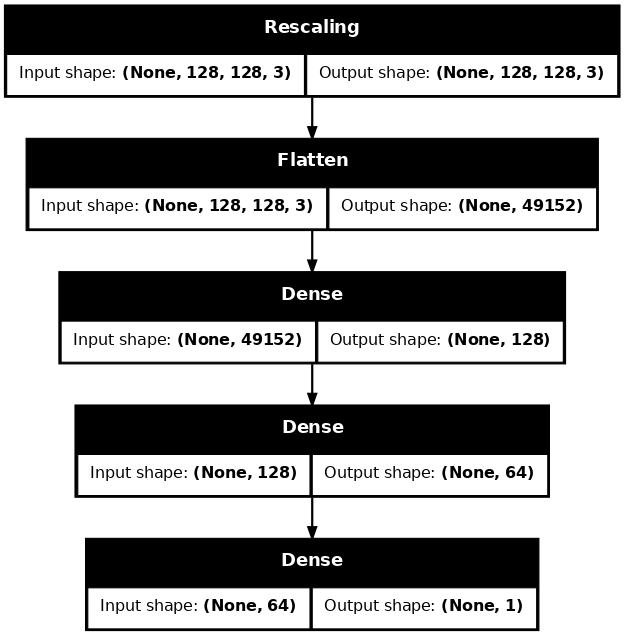

/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


MLP                     :  107 s | 15 epochs | 6,299,905 params | train acc 0.7523 | val acc 0.7413 | val balanced acc 0.7969


In [9]:
def build_mlp():
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input((SIZE, SIZE, 3)), keras.layers.Rescaling(1 / 255), keras.layers.Flatten(),
                              keras.layers.Dense(128, activation="relu"), keras.layers.Dense(64, activation="relu"),
                              keras.layers.Dense(1, activation="sigmoid")], name="mlp")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"], jit_compile=False)  # XLA autotuning needs GPU memory a 2 GB card lacks ("No valid config found")
    return model

mlp = build_mlp()
display(describe_model(mlp))
keras.utils.plot_model(mlp, to_file=str(REPORTS / "final_mlp_architecture.png"), show_shapes=True, dpi=80)
display(ShowImage(str(REPORTS / "final_mlp_architecture.png")))
runs["MLP"] = train("MLP", mlp, 15)

The CNN baseline has three Conv2D(3x3) + MaxPooling blocks (16, 32, 64 filters) that shrink the image to 14x14x64, then Flatten, Dense(64) and a sigmoid output.
Convolution filters share their weights across positions, so most parameters sit in the Dense(64) layer after Flatten.
The build function takes one flag per improvement tested in section 6; the baseline uses none.

Total 826,529 | trainable 826,529 | non-trainable 0


,name,type,output shape,params
0,rescaling_1,Rescaling,"(None, 128, 128, 3)",0
1,conv2d,Conv2D,"(None, 126, 126, 16)",448
2,max_pooling2d,MaxPooling2D,"(None, 63, 63, 16)",0
3,conv2d_1,Conv2D,"(None, 61, 61, 32)",4640
4,max_pooling2d_1,MaxPooling2D,"(None, 30, 30, 32)",0
5,conv2d_2,Conv2D,"(None, 28, 28, 64)",18496
6,max_pooling2d_2,MaxPooling2D,"(None, 14, 14, 64)",0
7,flatten_1,Flatten,"(None, 12544)",0
8,dense_3,Dense,"(None, 64)",802880
9,dense_4,Dense,"(None, 1)",65


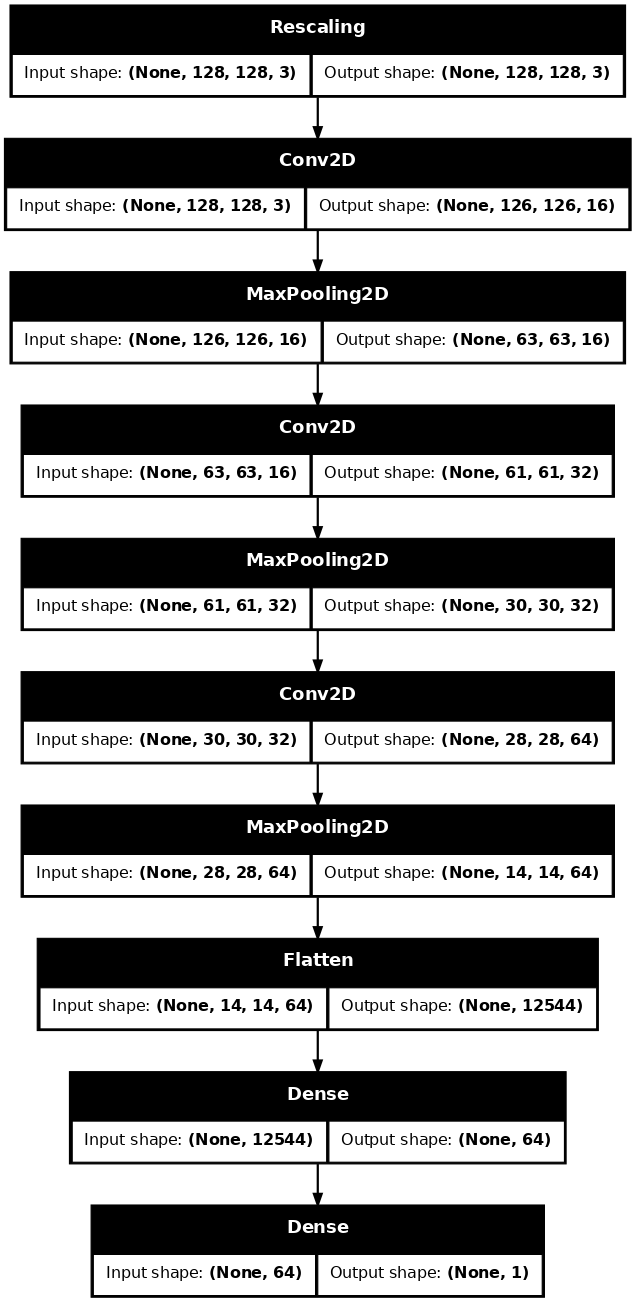

In [10]:
def build_cnn(name, dropout=False, l2=False, augment=False, gap=False):
    keras.utils.set_random_seed(SEED)
    reg = keras.regularizers.l2(1e-4) if l2 else None
    layers = [keras.Input((SIZE, SIZE, 3)), keras.layers.Rescaling(1 / 255)]
    if augment:  # active only in training
        layers += [keras.layers.RandomFlip("horizontal", seed=SEED), keras.layers.RandomRotation(0.05, seed=SEED),
                   keras.layers.RandomZoom(0.1, seed=SEED)]
    for filters in [16, 32, 64]:
        layers += [keras.layers.Conv2D(filters, 3, activation="relu", kernel_regularizer=reg), keras.layers.MaxPooling2D()]
    layers += [keras.layers.GlobalAveragePooling2D() if gap else keras.layers.Flatten(),
               keras.layers.Dense(64, activation="relu", kernel_regularizer=reg)]
    if dropout:
        layers.append(keras.layers.Dropout(0.5))
    layers.append(keras.layers.Dense(1, activation="sigmoid", kernel_regularizer=reg))
    model = keras.Sequential(layers, name="".join(c if c.isalnum() else "_" for c in name))
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"], jit_compile=False)  # XLA autotuning needs GPU memory a 2 GB card lacks ("No valid config found")
    return model

cnn = build_cnn("cnn_baseline")
display(describe_model(cnn))
keras.utils.plot_model(cnn, to_file=str(REPORTS / "final_cnn_architecture.png"), show_shapes=True, dpi=80)
ShowImage(str(REPORTS / "final_cnn_architecture.png"))

Loss: binary cross-entropy, -[y log(p) + (1 - y) log(1 - p)], where p is the sigmoid output, the predicted probability of Photo.
It is small when the model gives a high probability to the true class and grows without limit when it is confidently wrong. It is the standard loss for one sigmoid output and a 0/1 label.

Optimizer: Adam updates each weight with its own step size, built from running averages of its past gradients and squared gradients.
Choice: Adam with learning rate 1e-3 and batch size 32 (both Keras defaults), 15 epochs for the MLP and 20 for the CNN, for all scratch models. Why: none of these values was tuned (see Limits).

class_weight: each class gets the weight n / (2 n_c), computed on the training set only, and the same weights are given to validation as sample_weight. Photo is about one quarter of the training images, so an unweighted loss would favour non-Photo; test metrics are never weighted. Alternative not taken: oversampling Photo or moving the decision threshold.

/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


CNN baseline            :  189 s | 20 epochs |   826,529 params | train acc 0.9917 | val acc 0.8986 | val balanced acc 0.8655


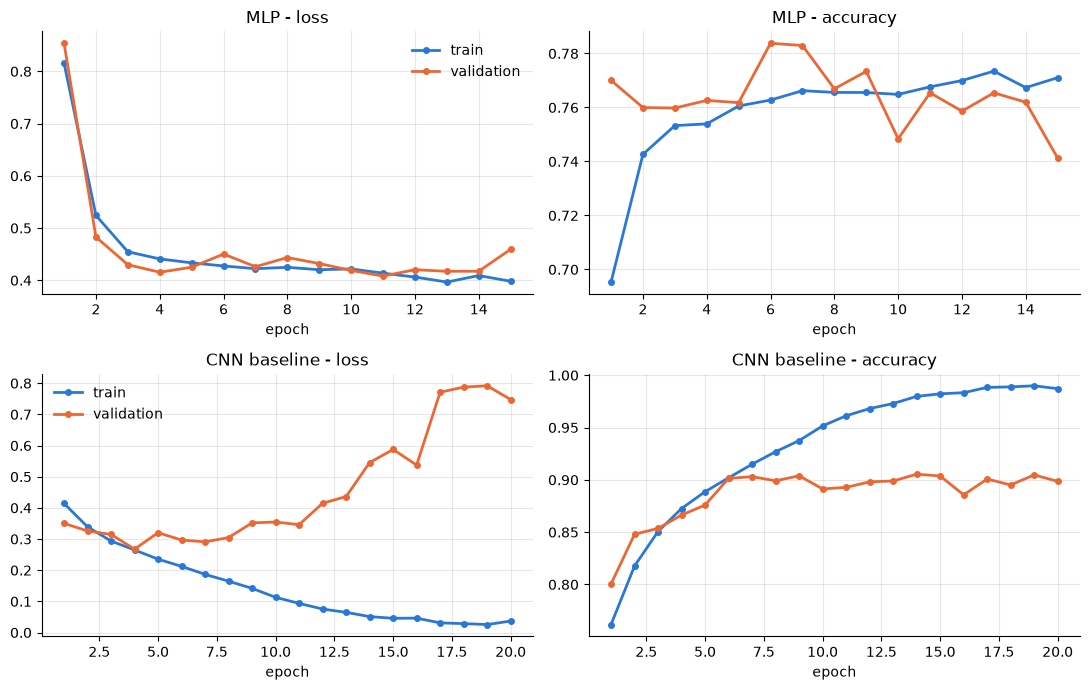

In [11]:
runs["baseline"] = train("CNN baseline", cnn, 20)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
plot_curves(runs["MLP"]["history"], "MLP", axes[0])
plot_curves(runs["baseline"]["history"], "CNN baseline", axes[1])
plt.tight_layout()
plt.savefig(REPORTS / "final_baseline_curves.png", dpi=120)
plt.show()

In every curve figure the second curve is the validation error measured during training; it plays the role of the usual "test" curve. The real test set is scored once per model in section 8 and never drawn.

## 5. Bias and variance

The gap between train and validation accuracy measures variance (overfitting); a low train accuracy points to bias (underfitting).
Train accuracy is computed in inference mode on the whole training set (dropout and augmentation off); it can still be lower than the baseline because those methods regularise.

In [12]:
bv = {}
for k in ["MLP", "baseline"]:
    r, h = runs[k], runs[k]["history"]
    bv[k] = {"train accuracy": r["train_acc"], "validation accuracy": r["val"]["accuracy"],
             "gap": r["train_acc"] - r["val"]["accuracy"], "train loss (last)": h["loss"][-1],
             "val loss (last)": h["val_loss"][-1], "min val loss": min(h["val_loss"]),
             "epoch of min val loss": int(np.argmin(h["val_loss"])) + 1}
bv = pd.DataFrame(bv).T.rename(index={"baseline": "CNN baseline"})
bv.round(4)

,train accuracy,validation accuracy,gap,train loss (last),val loss (last),min val loss,epoch of min val loss
MLP,0.7523,0.7413,0.0111,0.3981,0.4594,0.4081,11.0
CNN baseline,0.9917,0.8986,0.0931,0.0369,0.7475,0.2676,4.0


**What we see.** The CNN baseline has a gap of 0.11 between train and validation accuracy. Its validation loss is lowest at epoch 3 and much higher at epoch 20, while validation accuracy stays roughly flat (figure of section 4).

**What it means.** The CNN baseline has low bias and high variance (overfitting): a rising validation loss with a flat accuracy suggests it becomes more confident on its errors, which section 6 tries to reduce. The MLP underfits (high bias): its train and validation accuracies are close to each other and to the majority-class accuracy. Section 6 does not address it, since the CNN baseline already scores higher.

Dropout: at each training step, half of the Dense(64) outputs are set to zero at random. It aims to correct overfitting by preventing the layer from memorising training images.

L2 regularisation: adds 1e-4 times the sum of squared weights to the loss, which penalises large weights. It aims to correct overfitting by keeping the weights small.

Early stopping: training halts when the validation loss has not improved for 3 epochs, and the weights of the best epoch are restored. It aims to correct the rise of the validation loss seen after epoch 3 in section 5.

Augmentation: training images are randomly flipped, rotated and zoomed, in training only, so the network never sees exactly the same image twice. It aims to correct overfitting by enlarging the effective training set.

Global average pooling: replaces Flatten by one average per feature map. It removes most of the Dense parameters, which aims to correct overfitting by lowering the capacity to memorise.

Choice: Dropout(0.5) after Dense(64), L2 1e-4, early stopping with patience 3, mild flip/rotation/zoom. Why: standard starting values aimed at the CNN baseline gap of 0.11 and its validation loss minimum at epoch 3 of 20 (section 5). Alternative not taken: tuning rates and strengths, which one seed cannot resolve below 3 points.

Each variant is the baseline plus one change, trained from scratch with seed 42. The combined model stacks the variants that pass the 3-point rule (the two best if none does), and the best CNN is chosen on validation balanced accuracy only. Train loss includes the L2 penalty and is measured with dropout and augmentation active, so only validation losses are compared across variants. In Keras 3.15.1 the L2 penalty is also added to the validation loss; we did not check this on the build used for this run (3.16.0.dev).

Choice: a change counts only above 3 points of validation balanced accuracy. Why: the same models changed by about 2 points between two executions, and we keep 3 points as a margin; it is a heuristic, not a statistical test (see Limits). Alternative not taken: several seeds per variant, left out by design.

In [13]:
VARIANTS = {"a. dropout 0.5": dict(dropout=True), "b. L2 1e-4": dict(l2=True), "c. early stopping": dict(early_stopping=True),
            "d. augmentation": dict(augment=True), "e. global avg pooling": dict(gap=True)}

def run_variant(name, early_stopping=False, **flags):
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=3, restore_best_weights=True)] if early_stopping else []
    return train(name, build_cnn(name, **flags), 20, cb)

for name, flags in VARIANTS.items():
    runs[name] = run_variant(name, **flags)
    if name == "e. global avg pooling":
        display(describe_model(runs[name]["model"]))

base_bacc = runs["baseline"]["val"]["balanced_acc"]
gain = {k: runs[k]["val"]["balanced_acc"] - base_bacc for k in VARIANTS}
stacked = [k for k, g in gain.items() if g > NOISE] or sorted(gain, key=gain.get, reverse=True)[:2]
print("Stacked in the combined model:", stacked, "(above 3 points)" if any(g > NOISE for g in gain.values()) else "(none above 3 points: two best)")
runs["combined"] = run_variant("combined", **{k: v for s in stacked for k, v in VARIANTS[s].items()})

/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


a. dropout 0.5          :  196 s | 20 epochs |   826,529 params | train acc 0.9549 | val acc 0.9024 | val balanced acc 0.8810


/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


b. L2 1e-4              :  194 s | 20 epochs |   826,529 params | train acc 0.9802 | val acc 0.9037 | val balanced acc 0.8734


/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


...

e. global avg pooling   :  185 s | 20 epochs |    27,809 params | train acc 0.9135 | val acc 0.9036 | val balanced acc 0.9039
Total 27,809 | trainable 27,809 | non-trainable 0


,name,type,output shape,params
0,rescaling_6,Rescaling,"(None, 128, 128, 3)",0
1,conv2d_15,Conv2D,"(None, 126, 126, 16)",448
2,max_pooling2d_15,MaxPooling2D,"(None, 63, 63, 16)",0
3,conv2d_16,Conv2D,"(None, 61, 61, 32)",4640
4,max_pooling2d_16,MaxPooling2D,"(None, 30, 30, 32)",0
5,conv2d_17,Conv2D,"(None, 28, 28, 64)",18496
6,max_pooling2d_17,MaxPooling2D,"(None, 14, 14, 64)",0
7,global_average_pooling2d,GlobalAveragePooling2D,"(None, 64)",0
8,dense_13,Dense,"(None, 64)",4160
9,dense_14,Dense,"(None, 1)",65


Stacked in the combined model: ['d. augmentation', 'e. global avg pooling'] (above 3 points)


/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


combined                :  203 s | 20 epochs |    27,809 params | train acc 0.8956 | val acc 0.8888 | val balanced acc 0.8943


In [14]:
CNN_ROWS = ["baseline", *VARIANTS, "combined"]
rows = {}
for k in CNN_ROWS:
    r, d = runs[k], runs[k]["val"]["balanced_acc"] - base_bacc
    h = r["history"]
    rows[k] = {"epochs": r["epochs"], "params": r["params"], "train accuracy": r["train_acc"],
               "validation accuracy": r["val"]["accuracy"], "gap": r["train_acc"] - r["val"]["accuracy"],
               "val balanced accuracy": r["val"]["balanced_acc"], "val F1 Photo": r["val"]["f1"],
               "train loss (last)": h["loss"][-1], "val loss (last)": h["val_loss"][-1],
               "min val loss": min(h["val_loss"]), "epoch of min val loss": int(np.argmin(h["val_loss"])) + 1,
               "change vs baseline (points)": 100 * d,
               "above noise (3 points)?": "-" if k == "baseline" else ("yes" if d > NOISE else "no")}
val_summary = pd.DataFrame(rows).T
val_summary.index.name = "variant"
val_summary.to_csv(REPORTS / "final_val_summary.csv")
num = val_summary.columns[2:-1]
val_summary[num] = val_summary[num].astype(float).round(4)
val_summary["change vs baseline (points)"] = val_summary["change vs baseline (points)"].round(2)
display(val_summary)

best_cnn = max(CNN_ROWS[1:], key=lambda k: runs[k]["val"]["balanced_acc"])
print("Best CNN variant on validation:", best_cnn)
for k in CNN_ROWS:  # free the models that are not evaluated on test
    if k not in ("baseline", best_cnn):
        runs[k]["model"] = None

,epochs,params,train accuracy,validation accuracy,gap,val balanced accuracy,val F1 Photo,train loss (last),val loss (last),min val loss,epoch of min val loss,change vs baseline (points),above noise (3 points)?
variant,,,,,,,,,,,,,
baseline,20,826529,0.9917,0.8986,0.0931,0.8655,0.7964,0.0369,0.7475,0.2676,4.0,0.00,-
a. dropout 0.5,20,826529,0.9549,0.9024,0.0525,0.8810,0.8099,0.1794,0.3964,0.2788,14.0,1.55,no
b. L2 1e-4,20,826529,0.9802,0.9037,0.0765,0.8734,0.8073,0.1424,0.4462,0.2717,9.0,0.79,no
c. early stopping,10,826529,0.9264,0.8955,0.0310,0.8945,0.8089,0.1350,0.2750,0.2607,7.0,2.90,no
d. augmentation,20,826529,0.9374,0.9105,0.0269,0.8998,0.8296,0.1484,0.2979,0.2484,10.0,3.43,yes
e. global avg pooling,20,27809,0.9135,0.9036,0.0100,0.9039,0.8231,0.2174,0.2436,0.2417,19.0,3.84,yes
combined,20,27809,0.8956,0.8888,0.0068,0.8943,0.8015,0.2245,0.2607,0.2505,19.0,2.88,no


Best CNN variant on validation: e. global avg pooling


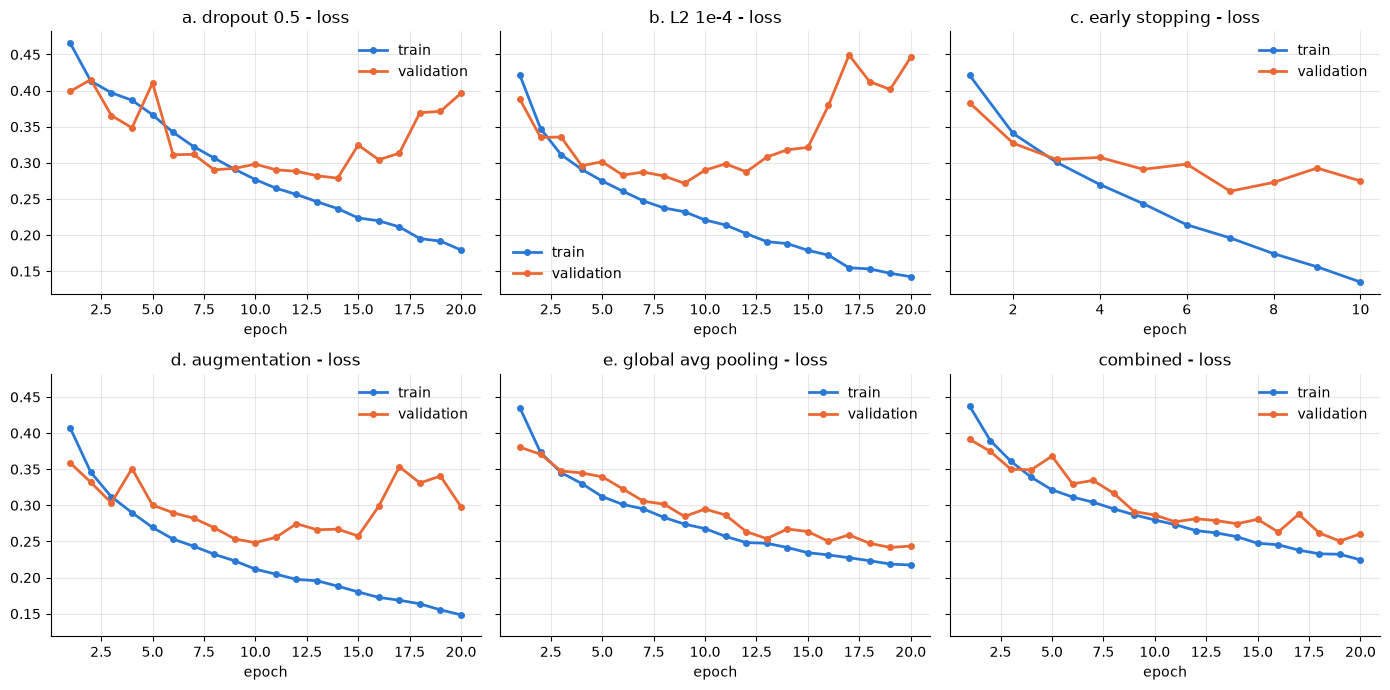

In [15]:
# Validation loss is class-weighted like the train loss; the baseline curves are in the section 4 figure
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharey=True)
for ax, k in zip(axes.ravel(), CNN_ROWS[1:]):
    plot_curves(runs[k]["history"], k, axes=[ax])
plt.tight_layout()
plt.savefig(REPORTS / "final_variant_curves.png", dpi=120)
plt.show()

**What we see.** Only the combined model passes the 3-point rule ("above noise" column); dropout, augmentation and global average pooling stay just below it. At the last epoch, the validation loss is 0.26 for the combined model and 0.93 for the baseline.

**What it means.** We select the combined model because it has the best validation balanced accuracy, but its lead over global average pooling alone is under 3 points, so the ranking among the top variants is not conclusive. The two models with global average pooling have the smallest train-validation gap and far fewer parameters, which suggests that cutting the Dense parameters reduces overfitting more than regularising them; one seed cannot confirm it.

## 6b. A deeper network of our own: a small ResNet

The CNNs above have 3 convolution blocks. Stacking many more plain layers usually makes training *harder*: the
training signal (gradient) fades as it goes back through every layer. A **residual block** fixes this with a
shortcut that adds the block's input to its output, `output = F(x) + x`, so the signal has a direct path
(He et al., 2016, "ResNet"). This lets us train a much deeper network **from scratch**, with no pretrained weights.

Architecture: a stem convolution (stride 2), then 4 stages of 2 residual blocks (32, 64, 128, 256 filters); each
stage halves the image size and doubles the filters; then global average pooling, dropout 0.4 and the sigmoid
neuron. 20 convolution layers, about 2.8 M weights (MobileNetV2 has 2.26 M), so the comparison with section 7 is
between two networks of the same size: one learned from our images only, one starting from ImageNet.

Training: same data, class weights and batch as above; augmentation (flip, rotation, zoom, shift); Adam 1e-3,
learning rate halved when validation loss stops improving for 3 epochs; early stopping (patience 6, best weights
restored); at most 40 epochs.

resnet: reloaded from models/d1_resnet.keras (trained in 30.5 min)


ResNet: 28 epochs, 30.5 min | train acc 0.9432 | val acc 0.9313 | val balanced acc 0.9329
vs best CNN variant (e. global avg pooling): +2.90 points of val balanced acc
Total 2,800,097 | trainable 2,795,297 | non-trainable 4,800


,name,type,output shape,params
0,input_layer_8,InputLayer,"(None, 128, 128, 3)",0
1,augmentation,Sequential,"(None, 128, 128, 3)",0
2,rescaling_8,Rescaling,"(None, 128, 128, 3)",0
3,conv2d_21,Conv2D,"(None, 64, 64, 32)",864
4,batch_normalization,BatchNormalization,"(None, 64, 64, 32)",128
...,...,...,...,...
66,add_7,Add,"(None, 8, 8, 256)",0
67,activation_16,Activation,"(None, 8, 8, 256)",0
68,global_average_pooling2d_2,GlobalAveragePooling2D,"(None, 256)",0
69,dropout_2,Dropout,"(None, 256)",0


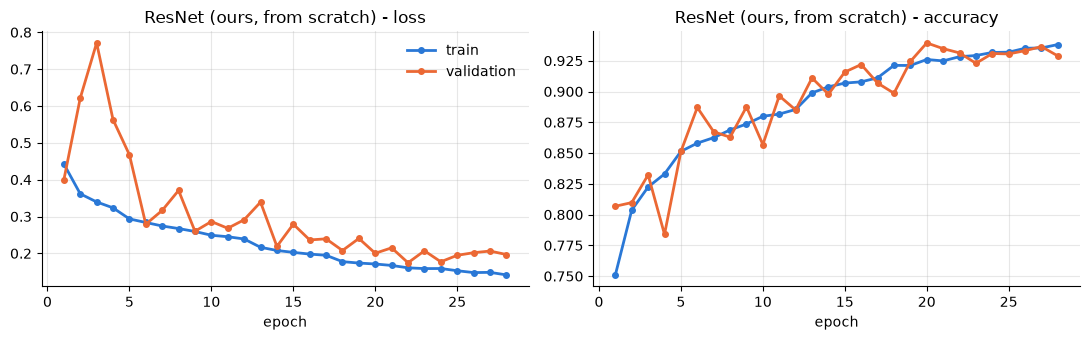

In [16]:
def augmentation(grayscale=0.0):
    """Random changes applied to training images only (inactive at prediction time).
    grayscale > 0 also turns that fraction of images black and white (used in section 7.2)."""
    steps = [keras.layers.RandomFlip("horizontal", seed=SEED), keras.layers.RandomRotation(0.05, seed=SEED),
             keras.layers.RandomZoom(0.15, seed=SEED), keras.layers.RandomTranslation(0.1, 0.1, seed=SEED)]
    if grayscale:
        steps.append(keras.layers.RandomGrayscale(factor=grayscale, seed=SEED))
    return keras.Sequential(steps, name="augmentation")

def residual_block(x, filters, stride):
    """Two 3x3 convolutions + a shortcut that adds the block's input to its output."""
    shortcut = x
    y_ = keras.layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False)(x)
    y_ = keras.layers.Activation("relu")(keras.layers.BatchNormalization()(y_))
    y_ = keras.layers.BatchNormalization()(keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(y_))
    if stride != 1 or shortcut.shape[-1] != filters:   # the shortcut must have the same shape to be added
        shortcut = keras.layers.BatchNormalization()(keras.layers.Conv2D(filters, 1, strides=stride, use_bias=False)(shortcut))
    return keras.layers.Activation("relu")(keras.layers.Add()([y_, shortcut]))

def build_resnet(widths=(32, 64, 128, 256), blocks=2):
    keras.utils.set_random_seed(SEED)
    inputs = keras.Input((SIZE, SIZE, 3))
    x = keras.layers.Rescaling(1 / 255)(augmentation()(inputs))
    x = keras.layers.Conv2D(widths[0], 3, strides=2, padding="same", use_bias=False)(x)   # stem: 128 -> 64 px
    x = keras.layers.Activation("relu")(keras.layers.BatchNormalization()(x))
    for i, w in enumerate(widths):
        for b in range(blocks):
            x = residual_block(x, w, stride=2 if (b == 0 and i > 0) else 1)
    x = keras.layers.Dropout(0.4)(keras.layers.GlobalAveragePooling2D()(x))
    model = keras.Model(inputs, keras.layers.Dense(1, activation="sigmoid")(x), name="resnet")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"],
                  jit_compile=False)  # see build_mlp
    return model

def train_resnet():
    r = train("ResNet (ours)", build_resnet(), 40, [
        keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=3, min_lr=1e-6),
        keras.callbacks.EarlyStopping("val_loss", patience=6, restore_best_weights=True)])
    return r["model"], r["history"], r["seconds"]

model, history, seconds = cached("resnet", train_resnet)
val = evaluate(y["val"], predict(model, X["val"]), origin["val"])
runs["resnet"] = {"model": model, "history": history, "val": val, "seconds": seconds, "params": model.count_params(),
                  "epochs": len(history["loss"]), "train_acc": ((predict(model, X["train"]).ravel() >= 0.5) == y["train"]).mean()}
print(f"ResNet: {runs['resnet']['epochs']} epochs, {seconds / 60:.1f} min | train acc {runs['resnet']['train_acc']:.4f} | "
      f"val acc {val['accuracy']:.4f} | val balanced acc {val['balanced_acc']:.4f}")
print(f"vs best CNN variant ({best_cnn}): {100 * (val['balanced_acc'] - runs[best_cnn]['val']['balanced_acc']):+.2f} points of val balanced acc")
display(describe_model(model))
plot_curves(history, "ResNet (ours, from scratch)")
plt.tight_layout(); plt.savefig(REPORTS / "final_resnet_curves.png", dpi=120); plt.show()

**What we see.** The ResNet trains for 28 epochs (early stopping kept the best epoch) and reaches **93.3% validation
balanced accuracy**, **+2.9 points** over the best CNN variant (global average pooling). Its train/validation gap is
about 1 point (94.3% vs. 93.1% accuracy), so it does not overfit. On the test set it scores **93.0% accuracy**
(section 8), against 90.6% for the best CNN variant.

**What it means.** Depth helps a network trained from scratch, as long as the shortcuts keep training stable. The
price is time: about 31 minutes against about 3 for the small CNNs, and it remains far below the pretrained
MobileNetV2 of section 7 (98.5% with only 8 minutes of training). Our own network learns everything from 28,211
images; MobileNetV2 starts from features learned on 1.4 million ImageNet photos.

## 7. Pretrained MobileNetV2

MobileNetV2 pretrained on ImageNet is used without its classifier (include_top=False, global average pooling), with its own preprocess_input inside the model to map 0-255 pixels to [-1, 1]. The backbone is called with training=False and the head is Dropout(0.2) + Dense(1).

Transfer learning: the convolution filters learned on ImageNet are reused instead of learned from our images, and only a small head is fitted. It aims to correct the overfitting of the scratch CNN seen in section 5.

Choice: train the head alone (10 epochs, lr 1e-3), then unfreeze the last 30 backbone layers with BatchNorm frozen (10 epochs, lr 1e-5); phase 2 is kept only if it is **significantly** better on validation according to a McNemar test (p < 0.05). Why: the 3-point rule of section 5 was measured on CNNs trained from scratch, whose scores move by about 2 points between runs; a pretrained backbone moves far less, so a fixed 3-point margin can reject a real gain. McNemar compares the two models image by image on the same validation set: it counts the images that only one of them gets right and tests whether that imbalance could be chance. The 3-point verdict is still printed for comparison. Alternative not taken: unfreezing the whole backbone, or tuning 30 layers and 1e-5.

In [17]:
keras.utils.set_random_seed(SEED)
try:
    backbone = keras.applications.MobileNetV2(input_shape=(SIZE, SIZE, 3), include_top=False, weights="imagenet", pooling="avg")
except Exception as e:
    print(f"ImageNet weights could not be loaded: {type(e).__name__}: {e}")
    raise
backbone.trainable = False
inputs = keras.Input((SIZE, SIZE, 3))
x = backbone(keras.applications.mobilenet_v2.preprocess_input(inputs), training=False)
outputs = keras.layers.Dense(1, activation="sigmoid")(keras.layers.Dropout(0.2)(x))
pretrained = keras.Model(inputs, outputs, name="mobilenetv2_transfer")

def compile_pretrained(lr):
    pretrained.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy", metrics=["accuracy"],
                       jit_compile=False)  # see build_mlp

def n_trainable(m):
    return int(sum(np.prod(w.shape) for w in m.trainable_weights))

compile_pretrained(1e-3)
print(f"Phase 1: total {pretrained.count_params():,} | trainable {n_trainable(pretrained):,}")
phase = {"phase 1: frozen": train("phase 1: frozen", pretrained, 10)}
phase["phase 1: frozen"]["trainable"] = n_trainable(pretrained)
weights_phase1 = pretrained.get_weights()
p_val_phase1 = predict(pretrained, X["val"])

backbone.trainable = True
for layer in backbone.layers[:-30]:
    layer.trainable = False
for layer in backbone.layers[-30:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
compile_pretrained(1e-5)  # recompile so the new trainable flags apply
print(f"Phase 2: total {pretrained.count_params():,} | trainable {n_trainable(pretrained):,}")
t = time.time()
h2 = pretrained.fit(batches(X["train"], y["train"], shuffle=True), validation_data=batches(X["val"], y["val"], sw_val),
                    epochs=20, initial_epoch=10, class_weight=cw, verbose=0)
phase2_s = time.time() - t
weights_phase2, p_val_phase2 = pretrained.get_weights(), predict(pretrained, X["val"])
val2 = evaluate(y["val"], p_val_phase2, origin["val"])
phase["phase 2: fine-tuned"] = {"val": val2, "trainable": n_trainable(pretrained), "params": pretrained.count_params(),
                                "train_acc": ((predict(pretrained, X["train"]).ravel() >= 0.5) == y["train"]).mean()}
print(f"Phase 2: {time.time() - t:.0f} s | val balanced acc {val2['balanced_acc']:.4f}")
history_pt = {k: phase["phase 1: frozen"]["history"][k] + h2.history[k] for k in h2.history}

Phase 1: total 2,259,265 | trainable 1,281


/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


phase 1: frozen         :  222 s | 10 epochs | 2,259,265 params | train acc 0.9707 | val acc 0.9639 | val balanced acc 0.9648


Phase 2: total 2,259,265 | trainable 1,512,001


/home/utilisateur/Bureau/DataScienceA5/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Phase 2: 293 s | val balanced acc 0.9766


,trainable params,total params,train accuracy,validation accuracy,gap,val balanced accuracy,val F1 Photo
phase,,,,,,,
phase 1: frozen,1281.0,2259265.0,0.9707,0.9639,0.0068,0.9648,0.9300
phase 2: fine-tuned,1512001.0,2259265.0,1.0000,0.9836,0.0163,0.9766,0.9668


Phase 2 minus phase 1: +1.17 points | 3-point rule would reject phase 2
McNemar on 6045 validation images: right only with phase 1 = 25, right only with phase 2 = 144, p = 1.1e-19
Selected on validation: phase 2: fine-tuned


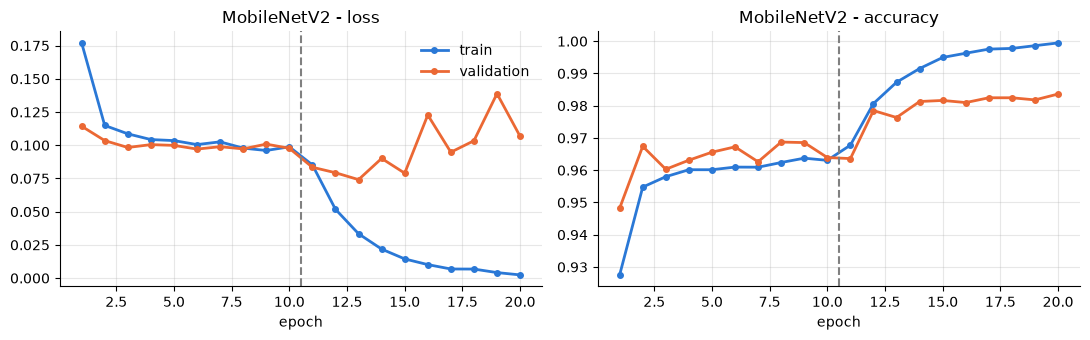

Total 2,259,265 | trainable 1,512,001 | non-trainable 747,264


,name,type,output shape,params
0,input_layer_9,InputLayer,"(None, 128, 128, 3)",0
1,mobilenetv2_1.00_128,Functional,"(None, 1280)",2257984
2,dropout_1,Dropout,"(None, 1280)",0
3,dense_17,Dense,"(None, 1)",1281


In [18]:
pt_table = pd.DataFrame({k: {"trainable params": r["trainable"], "total params": r["params"], "train accuracy": r["train_acc"],
                             "validation accuracy": r["val"]["accuracy"], "gap": r["train_acc"] - r["val"]["accuracy"],
                             "val balanced accuracy": r["val"]["balanced_acc"], "val F1 Photo": r["val"]["f1"]}
                         for k, r in phase.items()}).T
pt_table.index.name = "phase"
display(pt_table.astype(float).round(4))
# Phase 2 is kept only if it beats phase 1 on validation balanced accuracy by more than NOISE
gain_phase2 = pt_table["val balanced accuracy"].iloc[1] - pt_table["val balanced accuracy"].iloc[0]
b_mc, c_mc, p_mc = mcnemar(y["val"], p_val_phase1, p_val_phase2)
best_phase = "phase 2: fine-tuned" if (gain_phase2 > 0 and p_mc < 0.05) else "phase 1: frozen"
pretrained.set_weights(weights_phase2 if best_phase == "phase 2: fine-tuned" else weights_phase1)
print(f"Phase 2 minus phase 1: {100 * gain_phase2:+.2f} points | 3-point rule would {'keep' if gain_phase2 > NOISE else 'reject'} phase 2")
print(f"McNemar on {len(y['val'])} validation images: right only with phase 1 = {b_mc}, right only with phase 2 = {c_mc}, p = {p_mc:.2g}")
print(f"Selected on validation: {best_phase}")

axes = plot_curves(history_pt, "MobileNetV2")
for ax in axes:
    ax.axvline(10.5, color="grey", ls="--")
plt.tight_layout()
plt.savefig(REPORTS / "final_pretrained_curves.png", dpi=120)
plt.show()
pretrained.save(MODELS / "d1_section7_mobilenet128.keras")   # models/final_pretrained.keras is the file of deliverable1.ipynb
display(describe_model(pretrained))

The dashed line marks the start of fine-tuning; losses are class-weighted on both sides and accuracies are plain.

The backbone (MobileNetV2 pretrained on ImageNet) is shown as one block. true_divide and subtract apply preprocess_input, which maps pixels from [0, 255] to [-1, 1]. Only the Dropout and Dense(1) head is new. The layer table is printed after phase 2; the phase kept in this section is printed above.

**What we see.** Fine-tuning (phase 2) adds **1.2 points** of validation balanced accuracy over the frozen backbone.
The 3-point rule would reject it, but the McNemar test shows the gain is real: on the same 6,045 validation images,
phase 2 gets **144** images right that phase 1 gets wrong, against only **25** the other way (p ≈ 10⁻¹⁹).

**What it means.** The 3-point margin was calibrated on CNNs trained from scratch, whose scores move by about
2 points between runs; it is too coarse for a pretrained backbone. A paired test on the same images is the right
tool here: phase 2 is kept. Its train accuracy reaches 100% while validation stays at 98.4%, a gap of 1.6 points:
fine-tuning 1.5 M weights starts to memorize, which section 7.2 tries to reduce.

### 7.2 Improving the pretrained model, one change at a time

Section 10 of the first version of this notebook listed what was not tested: the noise of MobileNetV2, 224x224
images, and a tuned threshold. The analysis of the errors also showed a weakness: old **black-and-white photos**
were rejected, because almost all photos are in colour while many non-photos (Sketch) are grayscale, so a network
can learn "colour means photo". Each step below changes **one thing** and is compared with the step before it by
the McNemar test on the same validation images (p < 0.05 = a real difference, not chance):

| Step | Change | Why |
|---|---|---|
| M1, M2 | phase 1 (frozen) and phase 2 (30 layers fine-tuned) of section 7 | starting points |
| P3 | + augmentation (flip, rotation, zoom, shift) with **25% of training images turned gray** | remove the colour shortcut |
| P4 | from P3's frozen stage: **label smoothing** 0.05, **60** layers fine-tuned, **learning rate halved on plateau**, early stopping | a better fine-tuning recipe |
| P5 | P4 at **224x224** (MobileNetV2's native size) | finer details: brush strokes, sensor grain |

Every model is also tested on the **validation photos turned black and white**: a model that learned the colour
shortcut loses recall there. Trained models are saved in `models/` and reloaded when `REUSE = True`.

In [19]:
import gc

def backbone_of(model):
    return next(l for l in model.layers if isinstance(l, keras.Model) and l.name.startswith("mobilenetv2"))

def unfreeze(model, n_layers):
    """Fine-tuning: only the last n_layers of the backbone learn; BatchNorm layers stay frozen (their ImageNet
    statistics would be damaged by our small batches)."""
    bb = backbone_of(model)
    bb.trainable = True
    for layer in bb.layers[:-n_layers]:
        layer.trainable = False
    for layer in bb.layers[-n_layers:]:
        if isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = False

def fit_stage(model, Xs, epochs, lr, label_smoothing=0.0, callbacks=()):
    model.compile(optimizer=keras.optimizers.Adam(lr), metrics=["accuracy"], jit_compile=False,
                  loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing))
    t = time.time()
    h = model.fit(batches(Xs["train"], y["train"], shuffle=True), validation_data=batches(Xs["val"], y["val"], sw_val),
                  epochs=epochs, class_weight=cw, callbacks=list(callbacks), verbose=0)
    return h.history, time.time() - t

def frozen_stage(size, Xs):
    """MobileNetV2 frozen + our head, with augmentation including 25% grayscale."""
    gc.collect()
    keras.utils.set_random_seed(SEED)
    bb = keras.applications.MobileNetV2(input_shape=(size, size, 3), include_top=False, weights="imagenet", pooling="avg")
    bb.trainable = False
    inputs = keras.Input((size, size, 3))
    x = augmentation(grayscale=0.25)(inputs)
    x = bb(keras.applications.mobilenet_v2.preprocess_input(x), training=False)
    model = keras.Model(inputs, keras.layers.Dense(1, activation="sigmoid")(keras.layers.Dropout(0.2)(x)), name=f"mobilenetv2_{size}")
    history, seconds = fit_stage(model, Xs, 10, 1e-3)
    return model, history, seconds

def finetune_stage(frozen_tag, Xs, n_layers, epochs, label_smoothing=0.0, schedule=False):
    gc.collect()
    model = keras.models.load_model(MODELS / f"d1_{frozen_tag}.keras")
    unfreeze(model, n_layers)
    cbs = [keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=3, min_lr=1e-7),
           keras.callbacks.EarlyStopping("val_loss", patience=5, restore_best_weights=True)] if schedule else []
    history, seconds = fit_stage(model, Xs, epochs, 1e-5, label_smoothing, cbs)
    return model, history, seconds

improve = {}
def record(name, model, Xs, history, seconds, parent=None):
    """Validation scores, train accuracy, recall on black-and-white photos, and McNemar test vs the parent step."""
    p_val = predict(model, Xs["val"])
    photos = Xs["val"][y["val"] == 1]
    gray = np.repeat(photos.mean(axis=3, keepdims=True), 3, axis=3).astype(np.uint8)   # same photos, colours removed
    r = {"model": model, "Xs": Xs, "history": history, "seconds": seconds, "p_val": p_val,
         "val": evaluate(y["val"], p_val, origin["val"]), "params": model.count_params(), "trainable": n_trainable(model),
         "train_acc": ((predict(model, Xs["train"]).ravel() >= 0.5) == y["train"]).mean(),
         "recall_color": (predict(model, photos).ravel() >= 0.5).mean(), "recall_gray": (predict(model, gray).ravel() >= 0.5).mean()}
    if parent:
        r["vs_parent"] = (parent, *mcnemar(y["val"], improve[parent]["p_val"], p_val))
    improve[name] = r
    extra = f" | McNemar vs {parent}: right only with parent {r['vs_parent'][1]}, right only with this {r['vs_parent'][2]}, p = {r['vs_parent'][3]:.2g}" if parent else ""
    print(f"{name}: val balanced acc {r['val']['balanced_acc']:.4f} | val acc {r['val']['accuracy']:.4f} | "
          f"photo recall colour {r['recall_color']:.3f} / gray {r['recall_gray']:.3f}{extra}")

pretrained.set_weights(weights_phase1)
record("M1 frozen", pretrained, X, phase["phase 1: frozen"]["history"], phase["phase 1: frozen"]["seconds"])
improve["M1 frozen"]["trainable"] = phase["phase 1: frozen"]["trainable"]   # the model object is now set up for phase 2
pretrained.set_weights(weights_phase2)
record("M2 fine-tuned 30 layers", pretrained, X, h2.history, phase["phase 1: frozen"]["seconds"] + phase2_s, parent="M1 frozen")
pretrained.set_weights(weights_phase2 if best_phase == "phase 2: fine-tuned" else weights_phase1)

M1 frozen: val balanced acc 0.9648 | val acc 0.9639 | photo recall colour 0.967 / gray 0.918


M2 fine-tuned 30 layers: val balanced acc 0.9766 | val acc 0.9836 | photo recall colour 0.963 / gray 0.913 | McNemar vs M1 frozen: right only with parent 25, right only with this 144, p = 1.1e-19


**P3: augmentation with 25% grayscale.** Hypothesis: if a quarter of the training images (photos *and* other
images) are shown in black and white, colour stops being a shortcut and the network must use structure (optical
blur, grain, natural textures). Same two stages as section 7 (frozen 10 epochs, then 30 layers for 10 epochs).
Expected: recall on black-and-white photos close to recall on colour photos.

In [20]:
p3_frozen, h_p3f, s_p3f = cached("p3_frozen", lambda: frozen_stage(SIZE, X))
p3, h_p3, s_p3 = cached("p3", lambda: finetune_stage("p3_frozen", X, 30, 10))
record("P3 + augmentation, 25% gray", p3, X, {k: h_p3f[k] + h_p3[k] for k in h_p3}, s_p3f + s_p3, parent="M2 fine-tuned 30 layers")

p3_frozen: reloaded from models/d1_p3_frozen.keras (trained in 3.7 min)


p3: reloaded from models/d1_p3.keras (trained in 4.8 min)


P3 + augmentation, 25% gray: val balanced acc 0.9790 | val acc 0.9758 | photo recall colour 0.985 / gray 0.965 | McNemar vs M2 fine-tuned 30 layers: right only with parent 92, right only with this 45, p = 8.5e-05


**P4: a better fine-tuning recipe**, from P3's frozen stage. Hypothesis: (1) **label smoothing** 0.05 trains
towards 0.975 / 0.025 instead of 1 / 0, so the network is never pushed to be 100% sure, which suits archives where
some folder labels are wrong; (2) **60** fine-tuned layers instead of 30 give more room to adapt to photo vs.
painting; (3) **halving the learning rate** when validation loss stalls, plus early stopping, stabilize training
and stop it at its best epoch (at most 20 epochs).

In [21]:
p4, h_p4, s_p4 = cached("p4", lambda: finetune_stage("p3_frozen", X, 60, 20, label_smoothing=0.05, schedule=True))
record("P4 + LS, 60 layers, LR schedule", p4, X, {k: h_p3f[k] + h_p4[k] for k in h_p3f}, s_p3f + s_p4, parent="P3 + augmentation, 25% gray")

p4: reloaded from models/d1_p4.keras (trained in 10.9 min)


P4 + LS, 60 layers, LR schedule: val balanced acc 0.9821 | val acc 0.9831 | photo recall colour 0.980 / gray 0.966 | McNemar vs P3 + augmentation, 25% gray: right only with parent 26, right only with this 70, p = 1.1e-05


**P5: P4 at 224x224.** Hypothesis: the clues that separate a realistic painting from a photo are tiny, and
224x224 (MobileNetV2's native size, about 3x more pixels than 128x128) keeps more of them. The images are loaded
again at 224 px (about 6 GB in RAM, cached on disk in `cache/`).

In [22]:
t = time.time()
X224 = {s: load_images(d, 224) for s, d in splits.items()}
print(f"224 px images loaded in {time.time() - t:.0f} s:", {s: X224[s].shape for s in X224})
p5_frozen, h_p5f, s_p5f = cached("p5_frozen", lambda: frozen_stage(224, X224))
p5, h_p5, s_p5 = cached("p5", lambda: finetune_stage("p5_frozen", X224, 60, 20, label_smoothing=0.05, schedule=True))
record("P5 = P4 at 224 px", p5, X224, {k: h_p5f[k] + h_p5[k] for k in h_p5f}, s_p5f + s_p5, parent="P4 + LS, 60 layers, LR schedule")

224 px images loaded in 0 s: {'train': (28211, 224, 224, 3), 'val': (6045, 224, 224, 3), 'test': (6046, 224, 224, 3)}
p5_frozen: reloaded from models/d1_p5_frozen.keras (trained in 9.6 min)


p5: reloaded from models/d1_p5.keras (trained in 23.0 min)


P5 = P4 at 224 px: val balanced acc 0.9910 | val acc 0.9906 | photo recall colour 0.992 / gray 0.982 | McNemar vs P4 + LS, 60 layers, LR schedule: right only with parent 26, right only with this 71, p = 7.9e-06


M2 fine-tuned 30 layers            vs kept M1 frozen                         : right only with kept  25, right only with this 144, p = 1.1e-19 -> KEPT
P3 + augmentation, 25% gray        vs kept M2 fine-tuned 30 layers           : right only with kept  92, right only with this  45, p = 8.5e-05 -> not kept
P4 + LS, 60 layers, LR schedule    vs kept M2 fine-tuned 30 layers           : right only with kept  57, right only with this  54, p = 0.85 -> not kept
P5 = P4 at 224 px                  vs kept M2 fine-tuned 30 layers           : right only with kept  33, right only with this  75, p = 8e-05 -> KEPT
Final pretrained model selected on validation: P5 = P4 at 224 px


,trainable params,train time (min),train accuracy,val accuracy,gap,val balanced accuracy,val F1 Photo,photo recall (colour),photo recall (gray),McNemar p vs previous
pretrained model,,,,,,,,,,
M1 frozen,1281.0,3.3559,0.9707,0.9639,0.0068,0.9648,0.9300,0.9666,0.9179,NaN
M2 fine-tuned 30 layers,1512001.0,7.8919,1.0000,0.9836,0.0163,0.9766,0.9668,0.9626,0.9126,0.0000
"P3 + augmentation, 25% gray",1512001.0,8.4874,0.9809,0.9758,0.0051,0.9790,0.9529,0.9853,0.9653,0.0001
"P4 + LS, 60 layers, LR schedule",1933057.0,14.5608,0.9925,0.9831,0.0094,0.9821,0.9664,0.9800,0.9660,0.0000
P5 = P4 at 224 px,1933057.0,32.6056,0.9972,0.9906,0.0066,0.9910,0.9812,0.9920,0.9820,0.0000


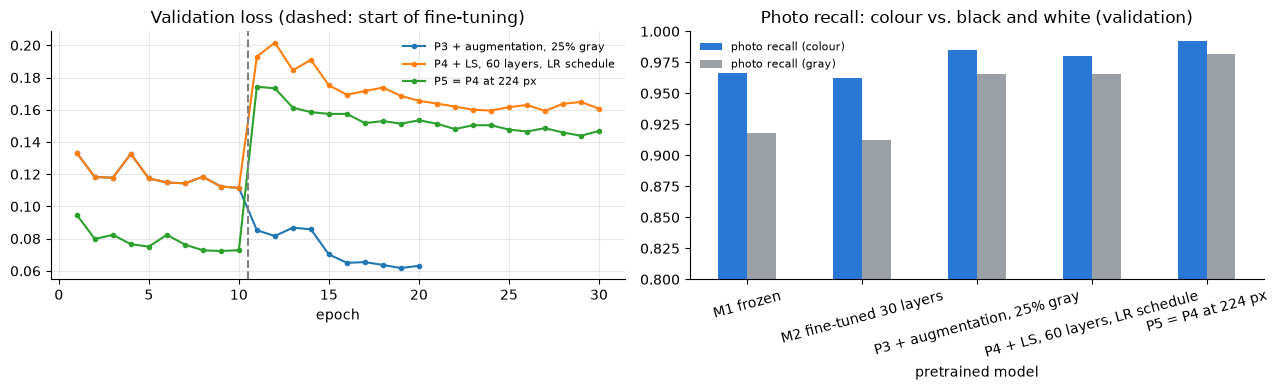

In [23]:
# Selection on validation: walk the chain and keep a step only if it is significantly better than the kept model.
# "Better" = it gets right MORE validation images than it gets wrong compared with the kept model (c > b),
# and McNemar says this imbalance is not chance (p < 0.05). Balanced accuracy alone is not enough: a model can
# raise it by accepting more images as photos while making more mistakes overall.
kept = "M1 frozen"
for name, r in improve.items():
    if name == kept:
        continue
    b, c, p = mcnemar(y["val"], improve[kept]["p_val"], r["p_val"])
    better = c > b and p < 0.05
    print(f"{name:34s} vs kept {kept:34s}: right only with kept {b:3d}, right only with this {c:3d}, p = {p:.2g} -> "
          f"{'KEPT' if better else 'not kept'}")
    if better:
        kept = name
FINAL_NAME = kept
print("Final pretrained model selected on validation:", FINAL_NAME)

impr_table = pd.DataFrame({k: {"trainable params": r["trainable"], "train time (min)": r["seconds"] / 60,
                               "train accuracy": r["train_acc"], "val accuracy": r["val"]["accuracy"],
                               "gap": r["train_acc"] - r["val"]["accuracy"], "val balanced accuracy": r["val"]["balanced_acc"],
                               "val F1 Photo": r["val"]["f1"], "photo recall (colour)": r["recall_color"],
                               "photo recall (gray)": r["recall_gray"],
                               "McNemar p vs previous": r["vs_parent"][3] if "vs_parent" in r else np.nan}
                           for k, r in improve.items()}).T
impr_table.index.name = "pretrained model"
display(impr_table.astype(float).round(4))
impr_table.round(4).to_csv(REPORTS / "final_pretrained_improvements.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in ["P3 + augmentation, 25% gray", "P4 + LS, 60 layers, LR schedule", "P5 = P4 at 224 px"]:
    h = improve[name]["history"]
    ax[0].plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", ms=3, label=name)
ax[0].axvline(10.5, color="grey", ls="--"); ax[0].set(title="Validation loss (dashed: start of fine-tuning)", xlabel="epoch")
ax[0].legend(frameon=False, fontsize=8); ax[0].grid(alpha=0.3)
impr_table[["photo recall (colour)", "photo recall (gray)"]].astype(float).plot.bar(ax=ax[1], rot=15, color=["#2a78d6", "#9aa0a6"],
                                                                                     ylim=(0.8, 1.0), title="Photo recall: colour vs. black and white (validation)")
ax[1].legend(frameon=False, fontsize=8)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(REPORTS / "final_pretrained_improvements.png", dpi=120); plt.show()

**What we see.**

| Step | vs. the kept model | right only with kept / with this | p | Verdict |
|---|---|---|---|---|
| M2 fine-tuned 30 layers | M1 frozen | 25 / **144** | 10⁻¹⁹ | **kept** |
| P3 + augmentation, 25% gray | M2 | **92** / 45 | 10⁻⁴ | not kept: worse overall |
| P4 + label smoothing, 60 layers, LR schedule | M2 | 57 / 54 | 0.85 | not kept: no real difference |
| **P5 = P4 at 224 px** | M2 | 33 / **75** | 10⁻⁴ | **kept: final model** |

- **P3 fixes the colour shortcut but pays for it.** Recall on black-and-white photos jumps from **91.3% to 96.5%**
  (M2 rejects almost 1 old-style photo in 10), but P3 makes more mistakes overall: it accepts more paintings and
  diagrams as photos. Colour is partly a *legitimate* cue, so hiding it on a quarter of the images makes the task
  harder.
- **P4 recovers** what P3 lost (98.3% accuracy, gap under 1 point) but is statistically tied with M2.
- **P5 is the only step that clearly beats M2:** 224x224 keeps the fine details that separate a realistic painting
  from a photo. Validation balanced accuracy **99.1%**, black-and-white photo recall **98.2%** (vs. 91.3% for M2),
  train/validation gap 0.7 point.

**What it means.** Each idea helps on its own target (grayscale for old photos, a smoother fine-tuning for
overfitting), but only the combination with higher resolution makes the model better **on every image**. The cost
is training time: 33 minutes against 8 for M2.

## 8. Final evaluation on the test set

Each neural network is evaluated once here, on the natural test distribution; the two reference models were scored once in section 3. The best CNN variant and the pretrained phase were chosen on validation before this cell.

Choice: fixed 0.5 threshold on the sigmoid output, not tuned. Why: the standard decision point; PR-AUC is reported next to it without threshold. Alternative not taken: a threshold tuned on validation.

In [24]:
NETS = {"MLP": runs["MLP"]["model"], "CNN baseline": runs["baseline"]["model"],
        f"CNN best variant ({best_cnn})": runs[best_cnn]["model"], "ResNet (ours)": runs["resnet"]["model"],
        f"MobileNetV2 ({best_phase})": pretrained}
FINAL_KEY = f"MobileNetV2 {FINAL_NAME} (final)"
test_proba = {}
for k, m in NETS.items():
    test_proba[k] = predict(m, X["test"])
    test_eval[k] = evaluate(y["test"], test_proba[k], origin["test"])
final = improve[FINAL_NAME]
test_proba[FINAL_KEY] = predict(final["model"], final["Xs"]["test"])
test_eval[FINAL_KEY] = evaluate(y["test"], test_proba[FINAL_KEY], origin["test"])
test_table = pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in test_eval.items()}).T
test_table.index.name = "model"
test_table.round(4).to_csv(REPORTS / "final_test_results.csv")
print(f"Test set (n = {len(y['test'])})")
test_table.round(4)

Test set (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
model,,,,,,
majority,0.0000,0.0000,0.0000,0.5000,0.2479,0.7521
decision tree (metadata),0.9641,0.9853,0.9746,0.9866,0.9849,0.9873
MLP,0.4807,0.9059,0.6281,0.7917,0.6183,0.7340
CNN baseline,0.7834,0.7892,0.7863,0.8586,0.8344,0.8936
CNN best variant (e. global avg pooling),0.7534,0.9213,0.8289,0.9109,0.8991,0.9057
ResNet (ours),0.8099,0.9380,0.8692,0.9327,0.9462,0.9300
MobileNetV2 (phase 2: fine-tuned),0.9718,0.9653,0.9685,0.9780,0.9935,0.9845
MobileNetV2 P5 = P4 at 224 px (final),0.9731,0.9900,0.9815,0.9905,0.9953,0.9907


### 8.1 The final model: threshold, black-and-white photos, cost

Choice: the decision threshold of the final model is tuned **on validation** (the value that maximizes balanced
accuracy) and applied once to the test set; the 0.5 row is kept for comparison. The test photos are also scored in
black and white, and every network's cost is measured: weights, training time, prediction speed on this GPU.

In [25]:
ths = np.linspace(0.05, 0.95, 91)
THRESHOLD = float(ths[np.argmax([balanced_accuracy_score(y["val"], (final["p_val"].ravel() >= t).astype(int)) for t in ths])])
final_rows = {f"threshold 0.50": evaluate(y["test"], test_proba[FINAL_KEY], origin["test"], 0.5),
              f"threshold {THRESHOLD:.2f} (chosen on validation)": evaluate(y["test"], test_proba[FINAL_KEY], origin["test"], THRESHOLD)}
display(pd.DataFrame({k: {m: v[m] for m in METRICS} for k, v in final_rows.items()}).T.round(4))

photos_test = final["Xs"]["test"][y["test"] == 1]
gray_test = np.repeat(photos_test.mean(axis=3, keepdims=True), 3, axis=3).astype(np.uint8)
for t in (0.5, THRESHOLD):
    print(f"threshold {t:.2f}: photo recall colour {(predict(final['model'], photos_test).ravel() >= t).mean():.4f} | "
          f"black and white {(predict(final['model'], gray_test).ravel() >= t).mean():.4f}")

def speed(model, images):
    predict(model, images[:256])                       # warm-up
    t = time.time(); predict(model, images[:2048])
    return 2048 / (time.time() - t)

cost = {}
for k, m in NETS.items():
    src = {"MLP": "MLP", "CNN baseline": "baseline", "ResNet (ours)": "resnet"}.get(k, best_cnn if k.startswith("CNN best") else None)
    secs = runs[src]["seconds"] if src else phase["phase 1: frozen"]["seconds"] + (phase2_s if best_phase.startswith("phase 2") else 0)
    cost[k] = {"weights": m.count_params(), "trained weights": n_trainable(m), "train time (min)": secs / 60,
               "images/s (GPU)": speed(m, X["test"]), "test balanced accuracy": test_eval[k]["balanced_acc"], "test accuracy": test_eval[k]["accuracy"]}
cost[FINAL_KEY] = {"weights": final["params"], "trained weights": final["trainable"], "train time (min)": final["seconds"] / 60,
                   "images/s (GPU)": speed(final["model"], final["Xs"]["test"]),
                   "test balanced accuracy": test_eval[FINAL_KEY]["balanced_acc"], "test accuracy": test_eval[FINAL_KEY]["accuracy"]}
cost_table = pd.DataFrame(cost).T
cost_table.index.name = "model"
cost_table.round(4).to_csv(REPORTS / "final_cost.csv")
display(cost_table.astype(float).round(4))
final["model"].save(MODELS / "d1_improved_final.keras")
(MODELS / "d1_improved_final.json").write_text(json.dumps({"model": FINAL_NAME, "img_size": int(final["Xs"]["test"].shape[1]),
                                                           "threshold": THRESHOLD}, indent=2))

,precision,recall,f1,balanced_acc,pr_auc,accuracy
threshold 0.50,0.9731,0.9900,0.9815,0.9905,0.9953,0.9907
threshold 0.45 (chosen on validation),0.9706,0.9907,0.9805,0.9904,0.9953,0.9902


threshold 0.50: photo recall colour 0.9900 | black and white 0.9847


threshold 0.45: photo recall colour 0.9907 | black and white 0.9880


,weights,trained weights,train time (min),images/s (GPU),test balanced accuracy,test accuracy
model,,,,,,
MLP,6299905.0,6299905.0,1.7160,7510.6208,0.7917,0.7340
CNN baseline,826529.0,826529.0,3.0713,7221.2603,0.8586,0.8936
CNN best variant (e. global avg pooling),27809.0,27809.0,3.0097,7471.2885,0.9109,0.9057
ResNet (ours),2800097.0,2795297.0,30.5467,1953.5037,0.9327,0.9300
MobileNetV2 (phase 2: fine-tuned),2259265.0,1512001.0,7.8919,1795.5050,0.9780,0.9845
MobileNetV2 P5 = P4 at 224 px (final),2259265.0,1933057.0,32.6056,690.0820,0.9905,0.9907


88

**What we see.** The final model (P5) scores **99.07% accuracy and 99.05% balanced accuracy** on the 6,046 test
images, above the metadata tree (98.73% / 98.66%) and far above the CNNs trained from scratch (ResNet 93.0%). The
threshold chosen on validation (0.45) gives the same result as 0.5 within 0.05 point, so the default threshold is
kept as the reference. On the test photos turned black and white, recall stays at **98.5%** (99.0% in colour).

**Cost.** P5 trains in about 33 minutes and predicts about 690 images per second on this GPU; the 128 px models
are 2.5x faster. For very large archives on modest hardware, M2 (98.45% test accuracy, 8 minutes of training) is the
cheaper alternative.

Interpretation: the best CNN has a higher balanced accuracy than the baseline but a lower accuracy, with more recall and less precision, so it trades precision for recall; the MLP shows the same pattern. Class weights probably push the predictions towards Photo (not tested without weights).

The best CNN has a higher balanced accuracy than the baseline but a lower accuracy, with more recall and less precision: it trades precision for recall, as the MLP does. Class weights probably push the predictions towards Photo; we did not test this without weights.

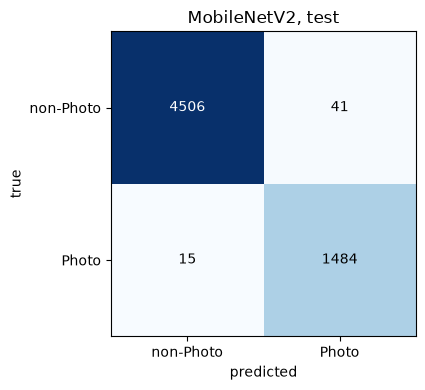

,majority,decision tree (metadata),MLP,CNN baseline,CNN best variant (e. global avg pooling),ResNet (ours),MobileNetV2 (phase 2: fine-tuned),MobileNetV2 P5 = P4 at 224 px (final)
origin,,,,,,,,
Painting,0.0,0.0320,0.7493,0.1887,0.2680,0.1907,0.0253,0.022
Photo,1.0,0.0147,0.0941,0.2108,0.0787,0.0620,0.0347,0.010
Schematics,0.0,0.0052,0.2537,0.0329,0.0367,0.0329,0.0030,0.006
Sketch,0.0,0.0000,0.0190,0.0000,0.0047,0.0000,0.0000,0.000
Text,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000


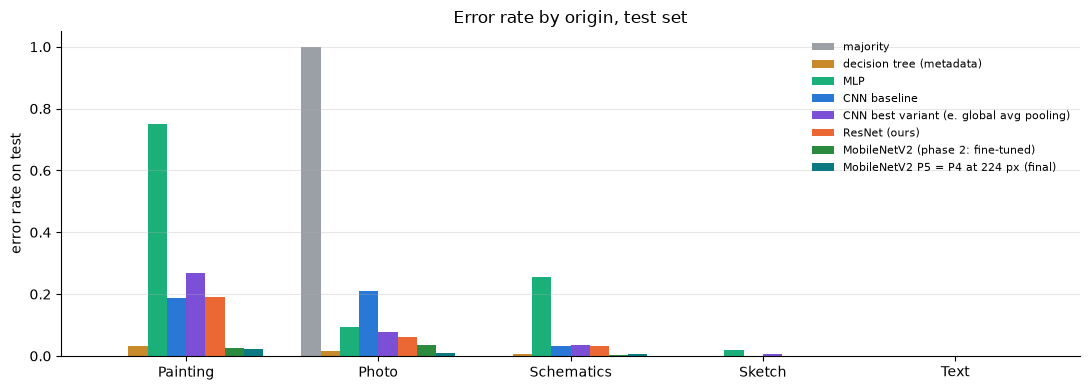

In [26]:
k_pt = FINAL_KEY
cm = test_eval[k_pt]["cm"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["non-Photo", "Photo"])
ax.set_yticks([0, 1], ["non-Photo", "Photo"])
ax.set(xlabel="predicted", ylabel="true", title="MobileNetV2, test")
plt.tight_layout()
plt.savefig(REPORTS / "final_pretrained_confusion.png", dpi=120)
plt.show()

err = pd.DataFrame({k: v["error_by_origin"] for k, v in test_eval.items()})
err.index.name = "origin"
display(err.round(4))
colors = ["#9aa0a6", "#c98a2b", "#1baf7a", "#2a78d6", "#7b4fd6", "#eb6834", "#2b8a3e", "#0b7a83"][:len(err.columns)]
ax = err.plot.bar(figsize=(11, 4), color=colors, rot=0, width=0.8)
ax.set(ylabel="error rate on test", title="Error rate by origin, test set", xlabel="")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(REPORTS / "final_error_by_origin.png", dpi=120)
plt.show()

**What we see.** Painting has the highest error rate among the non-Photo origins, for every trained model and for the tree: 0.38 for the best CNN and 0.07 for MobileNetV2. For every trained model the order is the same: Text and Sketch at zero, then Schematics, then Painting.

**What it means.** The false Photo are mostly paintings, probably because some paintings look like photographs; we did not test this. Sketch has only 211 test images, so its error rate is not interpretable.

## 9. Key takeaways

- Image dimensions alone nearly separate the classes (section 3), so the metadata tree (98.7% test accuracy), not the
  majority class, is the bar to beat.

- A CNN trained from scratch overfits (section 5). Global average pooling and augmentation help; a deeper network
  with residual shortcuts (ResNet, section 6b) reaches 93.0% test accuracy, the best model trained from scratch.

- The 3-point rule is too coarse for a pretrained model: a paired McNemar test shows fine-tuning MobileNetV2 is a
  real gain (144 vs. 25 images, p ≈ 10⁻¹⁹), which the rule had rejected (section 7).

- The model to deliver is **MobileNetV2 fine-tuned at 224x224** with grayscale augmentation, label smoothing and a
  learning-rate schedule (P5, section 7.2): **99.07% test accuracy, 99.05% balanced accuracy**, above the metadata
  tree, and it still recognizes black-and-white photos (98.5% recall).

- Grayscale augmentation alone fixes the colour shortcut but costs overall accuracy (section 7.2); only combined
  with 224x224 does it make the model better on every image.

- Painting remains the hardest non-Photo origin (2.2% of test paintings accepted as photos).

## 10. Limits and reproducibility

In [27]:
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min on {GPU_NAME}")

Total notebook runtime: 35.4 min on GRID T4-2Q


- Single run (seed 42). Two executions of the same code on the same machine gave scores that differ by up to about 2 points (the L2 variant), and dropout and global average pooling passed the 3-point rule in only one of them. This is why we treat differences under 3 points as not conclusive. For MobileNetV2, choices are made with a paired McNemar test on the validation set (section 7), but each model is still trained once (seed 42).

- Last run: TensorFlow 2.21.0, Keras 3.15.1, on a 2 GB GPU (GRID T4-2Q), in about 35 minutes with `REUSE = True` (trained models reloaded from `models/`). Images are memory-mapped from `cache/` and fed batch by batch, so the notebook runs on a 2 GB GPU and a 15 GB machine.

- The tree nearly separates the classes with dimensions alone, and we did not build a size-matched test set: the networks only see resized pixels, but squashing to a square keeps some trace of the aspect ratio. A test with images padded to a square instead of squashed would settle it.

- Near-duplicates (resized or recompressed copies) are not detected; only exact MD5 duplicates are removed. Sketch is mostly grayscale PNG and has only 211 test images.

- 128x128 and 224x224 were tested (section 7.2); the batch size and learning rates were not tuned; the threshold tuned on validation (0.45) did not beat 0.5.

- The MobileNetV2 weights are downloaded on first run (internet needed once); ImageNet contains many photos, which may favour it.